# Player positioning heatmaps — one game

Implements the [pipeline board](https://www.figma.com/board/FU9lMTi6j4VEAN9qKFPOHR/badminton-analysis-pipeline?node-id=0-1).

Run cells in order using the project's Python 3.12 environment. From the project root, install the existing extras with `uv sync --extra rtmpose --extra monotrack` and select that environment as the notebook kernel.

For each frame: detect a court matching the first frame, find exactly one player on each court half with confident feet, then keep the frame if **the shuttle moves OR both players move** within eight consecutive eligible frames. Rejected frames retain their frame IDs and missing positions. The first seven frames of each eligible run are window warm-up.

Player positions are the midpoint of the two foot centres **after projection into court metres**. Identities are near/far court sides for this one game, assumed to have no change of ends. The first frame is assumed reliable. Court and motion checks are the agreed approximate non-rally filter; same-view replays and active pauses can pass.

Heatmaps use a fixed **15 cm radius**, with original frame counts and dwell seconds retained. Neither player gets an independent colour normalization.

In [8]:
from pathlib import Path
import sys
import json
import time
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

project_root = next(p for p in (Path.cwd(), *Path.cwd().parents)
                    if (p / 'pyproject.toml').is_file())
sys.path.insert(0, str(project_root / 'src'))
from badminton_analysis.positions import (
    detect_court, court_agreement, align_court, wholebody_court_positions,
    motion_gate, position_heatmaps, court_model_corners, court_model_segments,
    court_width_m, court_length_m,
)

## Video and thresholds

The default input is the local BWF match, from **6:30 to 33:27** (end exclusive). To try the bundled 16-second clip, use its path with `start_seconds = 0` and `end_seconds = 16`. Set `max_frames = 240` for an initial short run, or leave it `None` for the whole game.

All image thresholds below use the **processing resolution**, which defaults to 960 pixels wide. Court acceptance checks line support at the fixed first-frame court. It does not refit or search for a new layout. These thresholds are starting values to tune empirically. Motion uses stance displacement in metres; the shuttle threshold measures maximum deviation from its mean detected pixel position over the window.

In [9]:
video_candidates = sorted((project_root / 'test_data').glob('*.webm'))
video_path = video_candidates[0] if video_candidates else project_root / 'test_data' / 'bwf-rally-06m29s-06m45s.mp4'
start_seconds = 6*60 + 30 if video_candidates else 0
end_seconds = 33*60 + 27 if video_candidates else 16
max_frames = 240

processing_width = 960
chunk_frames = 96
court_min_score = .45
court_max_lines = 40
foot_min_score = .4
court_margin_m = 1.
motion_window = 8
shuttle_deviation_px = 20.
player_displacement_m = .05
heatmap_radius_m = .15
heatmap_cell_m = .05
output_dir = project_root / '.cache' / 'player-position-heatmap'

## Bounded video decoding

TrackNet receives consecutive eight-frame windows before any filtering. Each chunk includes seven context frames on each side, and only its central frames are retained. Absolute source frame IDs are preserved. Only a chunk of resized images is held in memory; the small coordinate arrays are accumulated for plotting.

Dwell time is accepted-frame count divided by container FPS, assuming constant-rate normal playback. It measures observed time in this video, including any retained replay. It does not fill gaps.

In [10]:
def video_chunks(capture, first, stop, size, width):
    if size < 8 or width < 32 or first < 0 or stop-first < 8:
        raise ValueError('Need chunks >=8, width >=32 and a segment of at least eight frames.')
    capture.set(cv2.CAP_PROP_POS_FRAMES, first)
    frames = []
    buffer_start = next_frame = first
    for core_start in range(first, stop, size):
        core_stop = min(core_start + size, stop)
        read_stop = min(stop, core_stop + 7)
        while next_frame < read_stop:
            ok, frame = capture.read()
            if not ok:
                raise ValueError(f'Video decoding failed at source frame {next_frame}; no duration inferred for the gap.')
            height = round(frame.shape[0] * width / frame.shape[1])
            frames.append(cv2.resize(frame, (width, height), interpolation=cv2.INTER_AREA))
            next_frame += 1
        core = slice(core_start-buffer_start, core_stop-buffer_start)
        yield np.arange(core_start, core_stop), frames, core
        keep_from = max(first, core_stop-7)
        frames = frames[keep_from-buffer_start:]
        buffer_start = keep_from

## Small checks before inference

These verify perspective projection, low-confidence feet, court orientation, both motion paths, resets at rejected frames, empty heatmaps, dwell counts, and frame/context handling. No models or video downloads are needed for these checks.

In [11]:
_test_points = np.zeros((1, 133, 2))
_test_points[0, 17:23] = [[1, 2], [1.2, 2], [1.1, 1.6], [2, 2], [2.2, 2], [2.1, 1.6]]
_test_H = np.array([[100., 5., 30.], [2., 50., 40.], [.01, .02, 1.]])
_test_pixels = cv2.perspectiveTransform(_test_points, _test_H)
_test_scores = np.ones((1, 133))
_test_feet, _test_stance = wholebody_court_positions(_test_pixels, _test_scores, _test_H)
np.testing.assert_allclose(_test_stance, [[1.6, 1.8]], atol=1e-8)
_test_scores[0, 19] = 0
assert np.isnan(wholebody_court_positions(_test_pixels, _test_scores, _test_H)[1]).all()
_test_corners = cv2.perspectiveTransform(court_model_corners[None], _test_H)[0]
for _order in [[0, 1, 2, 3], [1, 0, 3, 2], [2, 3, 0, 1], [3, 2, 1, 0]]:
    _aligned, _error = align_court({'corners_px': _test_corners[_order]}, _test_corners)
    assert _error < 1e-5
    np.testing.assert_allclose(cv2.perspectiveTransform(court_model_corners[None], _aligned)[0], _test_corners, atol=1e-4)
_test_pos = np.tile([[2., 2.], [3., 10.]], (16, 1, 1))
_test_shuttle = np.full((16, 2), np.nan)
_test_valid = np.ones(16, bool)
assert not motion_gate(_test_pos, _test_shuttle, _test_valid).any()
_test_shuttle[:, 0] = np.arange(16)*10
_test_shuttle[:, 1] = 100
assert motion_gate(_test_pos, _test_shuttle, _test_valid)[7:].all()
_test_shuttle[:] = np.nan
_test_pos[:, :, 0] += np.arange(16)[:, None]*.02
assert motion_gate(_test_pos, _test_shuttle, _test_valid)[7:].all()
_test_pos[:, 1] = [3., 10.]
assert not motion_gate(_test_pos, _test_shuttle, _test_valid).any()
_test_valid[8] = False
_test_pos[:, 1, 0] += np.arange(16)*.02
_test_keep = motion_gate(_test_pos, _test_shuttle, _test_valid)
assert not _test_keep[8:16].any()
_test_maps = position_heatmaps(np.tile([[2., 2.], [3., 10.]], (10, 1, 1)), fps=20.)
np.testing.assert_allclose(_test_maps['frame_counts'].sum(axis=(1, 2)), [10, 10])
np.testing.assert_allclose(_test_maps['dwell_seconds'].max(axis=(1, 2)), [.5, .5])
assert not position_heatmaps(np.full((3, 2, 2), np.nan), 20.)['dwell_seconds'].any()

class _FakeCapture:
    def set(self, prop, value):
        self.index = int(value)
    def read(self):
        image = np.full((32, 32, 3), self.index, np.uint8)
        self.index += 1
        return True, image

_test_ids = []
for _ids, _frames, _core in video_chunks(_FakeCapture(), 10, 43, 8, 32):
    assert len(_frames) >= 8
    assert len(_frames) <= 8+14
    np.testing.assert_array_equal([int(f[0, 0, 0]) for f in _frames[_core]], _ids)
    _test_ids.extend(_ids)
np.testing.assert_array_equal(_test_ids, np.arange(10, 43))
print('Projection, motion, heatmap and chunk checks passed.')

_test_frame = np.full((540, 960, 3), 25, np.uint8)
_test_court_H = np.array([[65., 0., 200.], [0., 25., 80.], [0., 0., 1.]])
for _segment in cv2.perspectiveTransform(court_model_segments, _test_court_H):
    cv2.line(_test_frame, tuple(np.rint(_segment[0]).astype(int)),
             tuple(np.rint(_segment[1]).astype(int)), (255, 255, 255), 3)
_test_agreement = court_agreement(_test_frame, _test_court_H)
assert _test_agreement > .8, _test_agreement
_test_shifted_H = _test_court_H.copy()
_test_shifted_H[:2, 2] += 40
assert court_agreement(_test_frame, _test_shifted_H) < .45
assert court_agreement(np.zeros_like(_test_frame), _test_court_H) == 0
_test_offscreen_H = _test_court_H.copy()
_test_offscreen_H[:2, 2] += 2000
assert court_agreement(_test_frame, _test_offscreen_H) == 0
try:
    court_agreement(_test_frame, np.zeros((3, 3)))
except ValueError:
    pass
else:
    raise AssertionError('A singular homography must be rejected.')
print('Proposed-line checks pass for matching, shifted, blank and off-screen courts.')


Projection, motion, heatmap and chunk checks passed.
Proposed-line checks pass for matching, shifted, blank and off-screen courts.


## Inspect the first-frame court

This is the reference view for the entire selected game. Court coordinates start at the **near-left corner**, with Y increasing away from the camera. Subsequent frames are checked against those same projected markings and use this fixed homography. Player labels remain near/far sides.

Exhaustive court search runs only for the first frame. Later frames use the same stripe/structure-tensor mask and distance-based support score against the proposed markings, without Hough detection or layout search. Frames below `court_min_score` are skipped. Camera movement is not followed; the fixed-view assumption remains in effect.

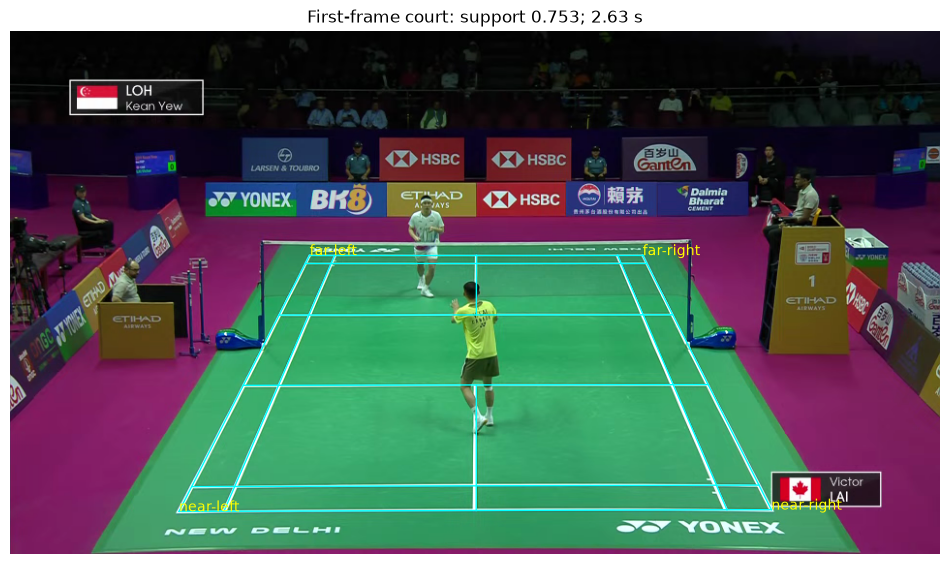

240 frames at 30.001238 FPS; source frames [11701, 11941).
One-time calibration: 2.63 s; later frames check the proposed lines without layout search.


In [12]:
if not video_path.is_file():
    raise FileNotFoundError(video_path)
if not np.isfinite([start_seconds, end_seconds]).all() or not 0 <= start_seconds < end_seconds:
    raise ValueError('Use finite start/end times with 0 <= start < end.')
if max_frames is not None and (not isinstance(max_frames, int) or max_frames < 8):
    raise ValueError('max_frames must be None or an integer >=8.')
if processing_width < 32 or chunk_frames < 8 or court_max_lines < 4:
    raise ValueError('Use processing_width >=32, chunk_frames >=8 and court_max_lines >=4.')
_thresholds = [court_min_score, foot_min_score, court_margin_m,
               shuttle_deviation_px, player_displacement_m]
if not np.isfinite(_thresholds).all() or not (0 <= court_min_score <= 1 and 0 <= foot_min_score <= 1):
    raise ValueError('Use finite thresholds and court/foot scores between 0 and 1.')
if min(shuttle_deviation_px, player_displacement_m) <= 0 or court_margin_m < 0 or motion_window < 2:
    raise ValueError('Use positive motion thresholds, a nonnegative margin, and window >=2.')

capture = cv2.VideoCapture(str(video_path))
try:
    fps = capture.get(cv2.CAP_PROP_FPS)
    total_frames = int(capture.get(cv2.CAP_PROP_FRAME_COUNT))
    if not capture.isOpened() or not np.isfinite(fps) or fps <= 0 or total_frames < 8:
        raise ValueError('Video must open with a valid FPS and frame count.')
    first_frame_id = int(np.ceil(start_seconds*fps))
    stop_frame_id = min(int(np.ceil(end_seconds*fps)), total_frames)
    if max_frames is not None:
        stop_frame_id = min(stop_frame_id, first_frame_id+max_frames)
    first_ids, first_images, _ = next(video_chunks(capture, first_frame_id, stop_frame_id, chunk_frames, processing_width))
    reference_image = first_images[0].copy()
finally:
    capture.release()

started = time.monotonic()
reference_layout = detect_court(reference_image, max_lines=court_max_lines)
court_seconds = time.monotonic()-started
if reference_layout['score'] < court_min_score:
    raise ValueError('First-frame court support is below court_min_score; inspect the input/thresholds.')
reference_corners = reference_layout['corners_px'].copy()
if reference_corners[:2, 1].mean() < reference_corners[2:, 1].mean():
    reference_corners = reference_corners[[3, 2, 1, 0]]
if reference_corners[0, 0] > reference_corners[1, 0]:
    reference_corners = reference_corners[[1, 0, 3, 2]]
reference_H, _ = align_court(reference_layout, reference_corners)
fig, axis = plt.subplots(figsize=(12, 7))
axis.imshow(cv2.cvtColor(reference_image, cv2.COLOR_BGR2RGB))
for segment in court_model_segments:
    pixels = cv2.perspectiveTransform(segment[None], reference_H)[0]
    axis.plot(*pixels.T, color='cyan', linewidth=1)
for name, pixel in zip(['near-left', 'near-right', 'far-right', 'far-left'], reference_corners):
    axis.annotate(name, pixel, color='yellow')
axis.set_title(f"First-frame court: support {reference_layout['score']:.3f}; {court_seconds:.2f} s")
axis.axis('off')
plt.show()
print(f'{stop_frame_id-first_frame_id:,} frames at {fps:.6f} FPS; source frames [{first_frame_id}, {stop_frame_id}).')
print(f'One-time calibration: {court_seconds:.2f} s; later frames check the proposed lines without layout search.')
del first_images

## Load existing local models

Reuse the local YOLO checkpoint for person boxes, RTMPose-l WholeBody for shoe landmarks, and the existing TrackNetV3 runner. The RTMPose and TrackNet helpers download their public checkpoints only if absent. No new dependencies are introduced.

In [13]:
import torch
from ultralytics import YOLO
from rtmlib import RTMPose
from rtmlib.tools.file import download_checkpoint
from badminton_analysis.monotrack.assets import fetch_tracknet
from badminton_analysis.monotrack.tracking import device_for, track

torch.set_num_threads(4)
inference_device = device_for()
person_checkpoint = project_root / 'yolo26m-pose.pt'
if not person_checkpoint.is_file():
    raise FileNotFoundError(f'Expected the existing local checkpoint: {person_checkpoint}')
person_detector = YOLO(str(person_checkpoint))
rtmpose_url = ('https://download.openmmlab.com/mmpose/v1/projects/rtmposev1/onnx_sdk/'
               'rtmpose-l_simcc-ucoco_dw-ucoco_270e-384x288-2438fd99_20230728.zip')
rtmpose_checkpoint = download_checkpoint(rtmpose_url, dst_dir=str(project_root / '.cache' / 'rtmpose'))
wholebody_pose = RTMPose(rtmpose_checkpoint, model_input_size=(288, 384),
                        to_openpose=False, backend='onnxruntime', device='cpu')
tracknet_checkpoint = fetch_tracknet(project_root / '.cache' / 'monotrack-assets')
print('Models ready; YOLO/TrackNet device:', inference_device)

load /Users/hydroxide/Desktop/Projects/badminton-analysis/.cache/rtmpose/rtmpose-l_simcc-ucoco_dw-ucoco_270e-384x288-2438fd99_20230728.onnx with onnxruntime backend
Models ready; YOLO/TrackNet device: mps


## Detect positions and shuttle, then apply motion filtering

Each later frame gets a line-support check against the first-frame court. Pose inference runs only when that score reaches `court_min_score`. Require exactly two people with measurable feet near the court, one in each half; ambiguous frames stay missing. Foot centres may lie up to the configured margin outside the painted boundaries. No interpolation or boundary clipping is applied.

The loop retains only coordinates after each chunk. Interrupting this cell stops processing; outputs are written by the final cell only after a completed run. TrackNet's background estimate is local to each context chunk, matching the existing rally experiment.

In [14]:
all_ids, all_positions, all_radii, all_shuttle, all_valid = [], [], [], [], []
capture = cv2.VideoCapture(str(video_path))
started = time.monotonic()
try:
    with tqdm(total=stop_frame_id-first_frame_id, desc='Game frames') as progress:
        for frame_ids, images, core in video_chunks(capture, first_frame_id, stop_frame_id, chunk_frames, processing_width):
            # shortcut: chunk-local median backgrounds can change TrackNet outputs; use a fixed view background when comparing chunk sizes.
            shuttle_chunk = np.asarray(track(images, tracknet_checkpoint, inference_device, batch_size=4), float)[core, :2]
            positions_chunk = np.full((len(frame_ids), 2, 2), np.nan)
            radii_chunk = np.full((len(frame_ids), 2), np.nan)
            valid_chunk = np.zeros(len(frame_ids), bool)
            for offset, image in enumerate(images[core]):
                progress.update(1)
                if frame_ids[offset] != first_frame_id and court_agreement(image, reference_H) < court_min_score:
                    continue
                H = reference_H
                result = person_detector.predict(image, classes=[0], conf=.25, imgsz=960,
                                                 device=str(inference_device), verbose=False)[0]
                boxes = result.boxes.xyxy.cpu().numpy()
                if not len(boxes):
                    continue
                keypoints, scores = wholebody_pose(image, bboxes=boxes)
                feet, stances = wholebody_court_positions(keypoints, scores, H, foot_min_score)
                near_court = (np.isfinite(stances).all(axis=1)
                              & (stances >= -court_margin_m).all(axis=1)
                              & (stances <= [court_width_m+court_margin_m, court_length_m+court_margin_m]).all(axis=1))
                candidates = np.flatnonzero(near_court)
                if len(candidates) != 2:
                    continue
                side = (stances[candidates, 1] >= court_length_m/2).astype(int)
                if set(side) != {0, 1}:
                    continue
                for index, slot in zip(candidates, side):
                    positions_chunk[offset, slot] = stances[index]
                    radii_chunk[offset, slot] = np.linalg.norm(feet[index, 0]-feet[index, 1])/2
                valid_chunk[offset] = True
            all_ids.extend(frame_ids)
            all_positions.extend(positions_chunk)
            all_radii.extend(radii_chunk)
            all_shuttle.extend(shuttle_chunk)
            all_valid.extend(valid_chunk)
finally:
    capture.release()

frame_ids = np.asarray(all_ids, dtype=int)
raw_positions = np.asarray(all_positions, dtype=float)
stance_radii = np.asarray(all_radii, dtype=float)
shuttle_pixels = np.asarray(all_shuttle, dtype=float)
eligible = np.asarray(all_valid, dtype=bool)
accepted = motion_gate(raw_positions, shuttle_pixels, eligible, motion_window,
                       shuttle_deviation_px, player_displacement_m)
positions = raw_positions.copy()
positions[~accepted] = np.nan
stance_radii[~accepted] = np.nan
print(f'Processed {len(frame_ids):,} frames in {(time.monotonic()-started)/60:.1f} minutes.')
print(f'Court + two-player checks: {eligible.sum():,}; motion accepted: {accepted.sum():,} ({accepted.mean():.1%}).')
print(f'Observed dwell per player: {accepted.sum()/fps:.2f} s; skipped frames contribute zero.')

Game frames: 100%|██████████| 240/240 [02:07<00:00,  1.89it/s]

Processed 240 frames in 2.1 minutes.
Court + two-player checks: 231; motion accepted: 203 (84.6%).
Observed dwell per player: 6.77 s; skipped frames contribute zero.


## Heatmaps and saved observations

The heatmap value at each grid cell is the number of accepted source frames whose estimated player position falls within **15 cm** of that cell, divided by FPS. This is local dwell time, not a probability distribution; overlapping circles mean summing heatmap cells is not total duration. Grid cells are approximately 5 cm wide. Raw unsmoothed bin counts are also retained.

The plot includes the court margin so positions outside the boundary remain visible. Both players share the same seconds scale. CSV rows retain every source frame and both players; missing positions have zero dwell time. The NPZ retains raw bins, circular-presence frame counts, seconds and grid edges. The settings JSON records FPS and processing choices needed to interpret those files. Rerunning this cell replaces this notebook's files in `.cache/player-position-heatmap/`.

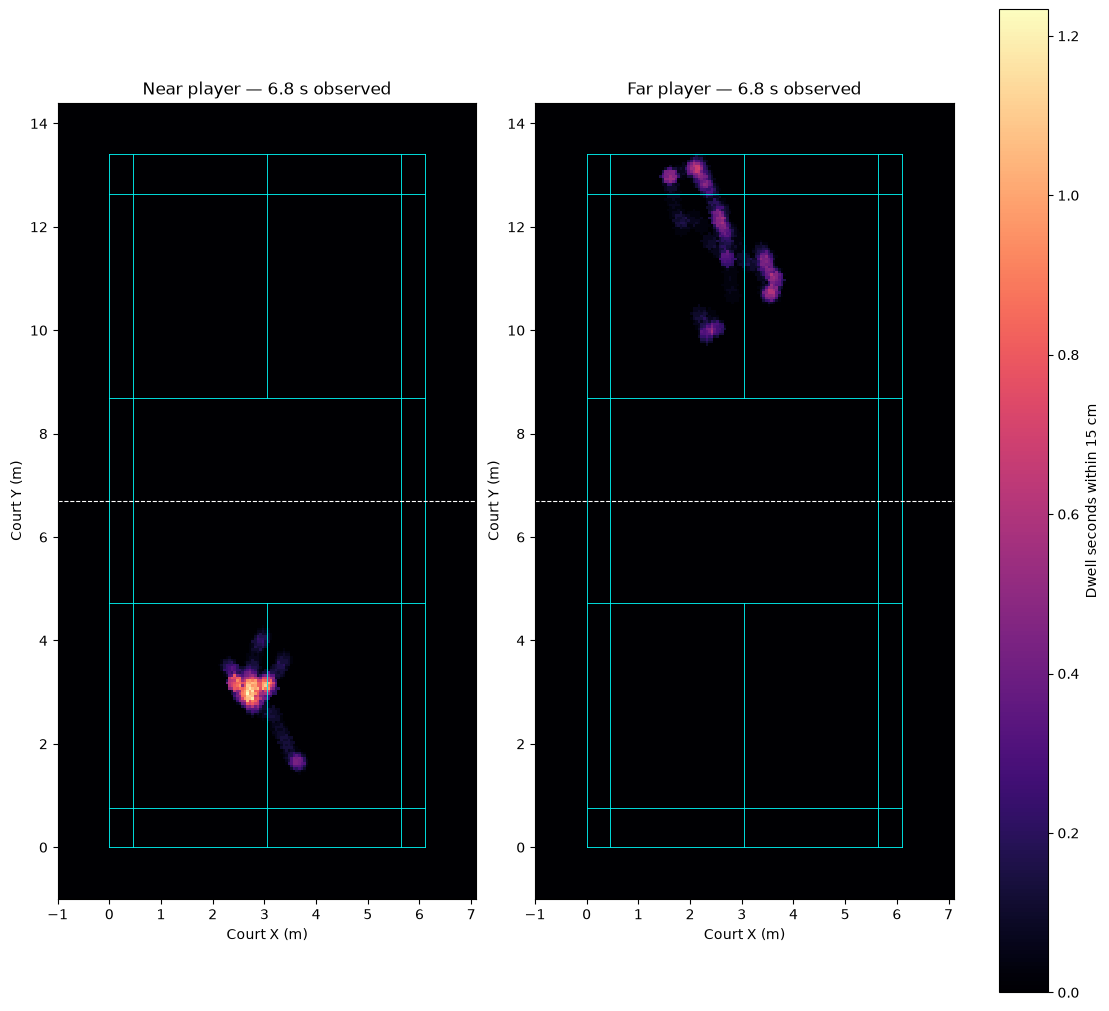

Saved: /Users/hydroxide/Desktop/Projects/badminton-analysis/.cache/player-position-heatmap


,frame,player,x_m,y_m,stance_radius_m,dwell_seconds
0,11701,near,NaN,NaN,NaN,0.0
1,11701,far,NaN,NaN,NaN,0.0
2,11702,near,NaN,NaN,NaN,0.0
3,11702,far,NaN,NaN,NaN,0.0
4,11703,near,NaN,NaN,NaN,0.0
5,11703,far,NaN,NaN,NaN,0.0
6,11704,near,NaN,NaN,NaN,0.0
7,11704,far,NaN,NaN,NaN,0.0
8,11705,near,NaN,NaN,NaN,0.0
9,11705,far,NaN,NaN,NaN,0.0


In [15]:
heatmaps = position_heatmaps(positions, fps, heatmap_radius_m, heatmap_cell_m, court_margin_m)
rows = []
for i, frame_id in enumerate(frame_ids):
    for slot, player in enumerate(['near', 'far']):
        rows.append({'frame': int(frame_id), 'player': player,
                     'x_m': positions[i, slot, 0], 'y_m': positions[i, slot, 1],
                     'stance_radius_m': stance_radii[i, slot],
                     'dwell_seconds': float(accepted[i])/fps})
observations = pd.DataFrame(rows)
output_dir.mkdir(parents=True, exist_ok=True)
observations.to_csv(output_dir / 'positions.csv', index=False)
np.savez_compressed(output_dir / 'heatmaps.npz', **heatmaps)
settings = {
    'video': str(video_path), 'fps': fps, 'source_frame_start': first_frame_id,
    'source_frame_stop': stop_frame_id, 'processed_frames': len(frame_ids),
    'accepted_frames_per_player': int(accepted.sum()), 'processing_width': processing_width,
    'chunk_frames': chunk_frames, 'court_min_score': court_min_score,
    'court_check': 'fixed-reference line support', 'court_max_lines': court_max_lines,
    'foot_min_score': foot_min_score, 'court_margin_m': court_margin_m,
    'motion_window': motion_window, 'shuttle_deviation_px': shuttle_deviation_px,
    'player_displacement_m': player_displacement_m, 'heatmap_radius_m': heatmap_radius_m,
    'heatmap_cell_m': heatmap_cell_m, 'reference_H_court_to_image': reference_H.tolist(),
}
(output_dir / 'settings.json').write_text(json.dumps(settings, indent=2)+'\n')

fig, axes = plt.subplots(1, 2, figsize=(11, 10), constrained_layout=True)
extent = [heatmaps['x_edges_m'][0], heatmaps['x_edges_m'][-1],
          heatmaps['y_edges_m'][0], heatmaps['y_edges_m'][-1]]
vmax = max(float(heatmaps['dwell_seconds'].max()), 1/fps)
for slot, axis in enumerate(axes):
    image = axis.imshow(heatmaps['dwell_seconds'][slot], extent=extent, origin='lower',
                        cmap='magma', vmin=0, vmax=vmax, interpolation='nearest')
    for segment in court_model_segments:
        axis.plot(*segment.T, color='cyan', linewidth=.6)
    axis.axhline(court_length_m/2, color='white', linestyle='--', linewidth=.8)
    axis.set(xlabel='Court X (m)', ylabel='Court Y (m)',
             title=f"{['Near', 'Far'][slot]} player — {accepted.sum()/fps:.1f} s observed")
    axis.set_aspect('equal')
fig.colorbar(image, ax=axes, label=f'Dwell seconds within {heatmap_radius_m*100:g} cm')
fig.savefig(output_dir / 'heatmaps.png', dpi=160)
plt.show()
if not accepted.any():
    print('No frames passed all checks. Inspect the calibration and thresholds before interpreting an empty map.')
print('Saved:', output_dir)
display(observations.head(10))